# Task 1

Hentet kode fra frosty nettside linje code box [1]-[3]


In [1]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pandas as pd
import requests

with open("client_id.txt", "r") as file:
    client_id = file.read().strip().split(":")[1].strip()


In [2]:
endpoint = 'https://frost.met.no/observations/v0.jsonld'
parameters = {
    'sources': 'SN17850',
    'elements': 'mean(air_temperature P1D)',
    'referencetime': '2025-01-01/2025-12-31',
}

# Issue an HTTP GET request
r = requests.get(endpoint, parameters, auth=(client_id,''))
# Extract JSON data
json = r.json()

In [3]:
# Check if the request worked, print out any errors
if r.status_code == 200:
    data = json['data']
    print('Data retrieved from frost.met.no!')
else:
    print('Error! Returned status code %s' % r.status_code)
    print('Message: %s' % json['error']['message'])
    print('Reason: %s' % json['error']['reason'])


Data retrieved from frost.met.no!


Tok inspirasjon fra Frosty code men den var utdatert box[4]

In [4]:
rows = []
for item in data:
    observation = item['observations'][0]
    rows.append({
        'date': pd.to_datetime(item['referenceTime']).tz_localize(None).normalize(),
        'source_Id': item['sourceId'],
        'element_Id': observation['elementId'],
        'temperature': observation['value'],
        'unit': observation['unit'],
        'time_offset': observation['timeOffset']
    })
df = pd.DataFrame(rows).set_index('date')

df.head()

,source_Id,element_Id,temperature,unit,time_offset
date,,,,,
2025-01-01,SN17850:0,mean(air_temperature P1D),-5.2,degC,PT0H
2025-01-02,SN17850:0,mean(air_temperature P1D),-11.5,degC,PT0H
2025-01-03,SN17850:0,mean(air_temperature P1D),-8.9,degC,PT0H
2025-01-04,SN17850:0,mean(air_temperature P1D),-15.5,degC,PT0H
2025-01-05,SN17850:0,mean(air_temperature P1D),-12.5,degC,PT0H


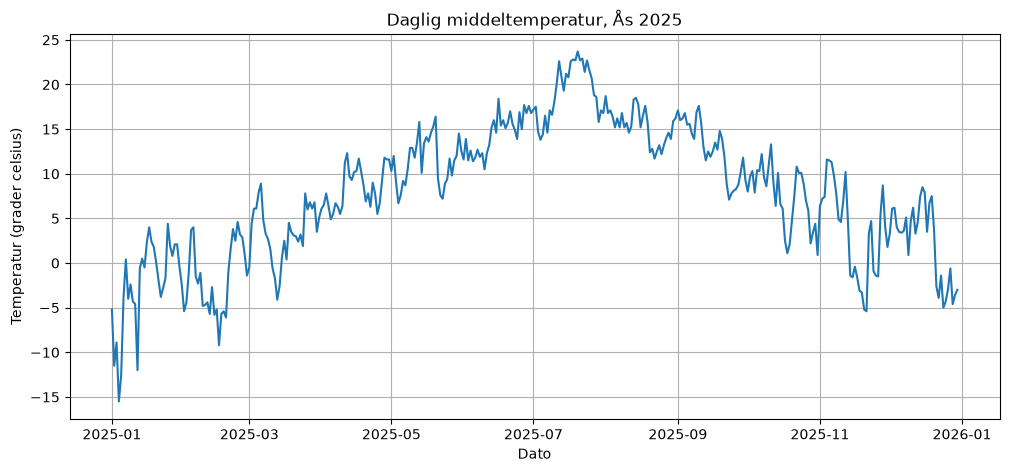

In [5]:
fig, ax = plt.subplots(figsize=(12, 5)) 
ax.plot(df.index,df['temperature'])
ax.set_title('Daglig middeltemperatur, Ås 2025')
ax.set_xlabel('Dato')
ax.set_ylabel('Temperatur (grader celsius)')
ax.grid()
plt.show()


In [6]:
print('Sammendrag av lufttemperatur, Ås 2025')
print('-' * len('Sammendrag av lufttemperatur, Ås 2025'))
print(f"{'Gjennomsnitt':<15}{df['temperature'].mean():>8.1f} °C")
print(f"{'Median':<15}{df['temperature'].median():>8.1f} °C")
print(f"{'Min':<15}{df['temperature'].min():>8.1f} °C")
print(f"{'Maks':<15}{df['temperature'].max():>8.1f} °C")

Sammendrag av lufttemperatur, Ås 2025
-------------------------------------
Gjennomsnitt        7.9 °C
Median              8.4 °C
Min               -15.5 °C
Maks               23.7 °C


# Task 2

Laget en def for å kunne gjenbruke i oppgave 3 og 4 slik at det ikke blir så mye repitisjon

In [7]:
def get_frost_periods(source_id, element, start, end, client_id):
    r = requests.get('https://frost.met.no/observations/v0.jsonld',
                     {'sources': source_id,
                      'elements': element,
                      'referencetime': f'{start}/{end}'},
                      auth=(client_id,''))
    if r.status_code != 200:
        err = r.json()['error']
        raise RuntimeError(f"{r.status_code}: {err['message']} - {err['reason']}")
    return pd.Series(
        {pd.to_datetime(d['referenceTime']).tz_localize(None).normalize():
         d['observations'][0]['value'] for d in r.json()['data']}
    ).sort_index()

precipitation = get_frost_periods('SN17850', 'sum(precipitation_amount P1D)', '2025-01-01', '2025-12-31', client_id)

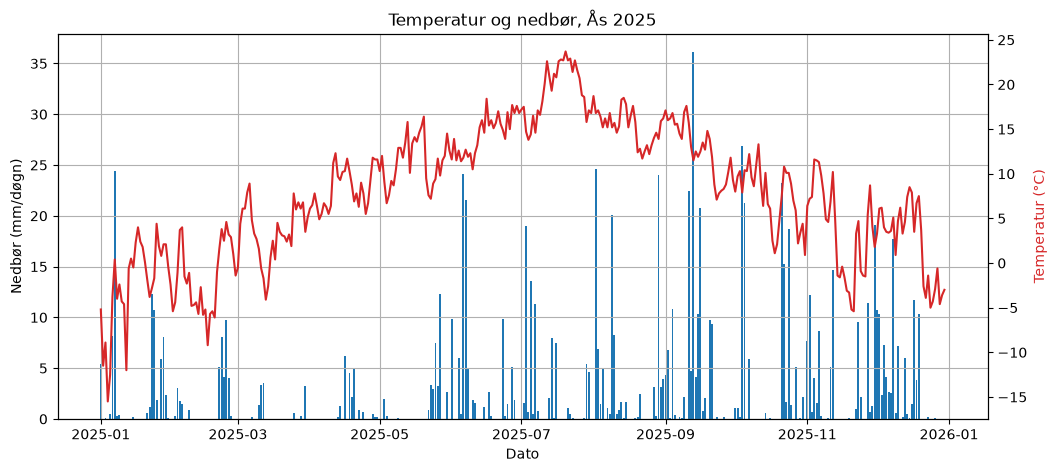

In [8]:
temperature = df['temperature']
fig, ax1 = plt.subplots(figsize=(12, 5)) 
ax1.bar(precipitation.index, precipitation.values)
ax1.set_xlabel('Dato')
ax1.set_ylabel('Nedbør (mm/døgn)')

ax2 = ax1.twinx()
ax2.plot(temperature.index, temperature.values, color='tab:red', label='Middeltemperatur (°C)')
ax2.set_ylabel('Temperatur (°C)', color='tab:red')

ax1.set_title('Temperatur og nedbør, Ås 2025')
ax1.grid()
plt.show()


# Task 3

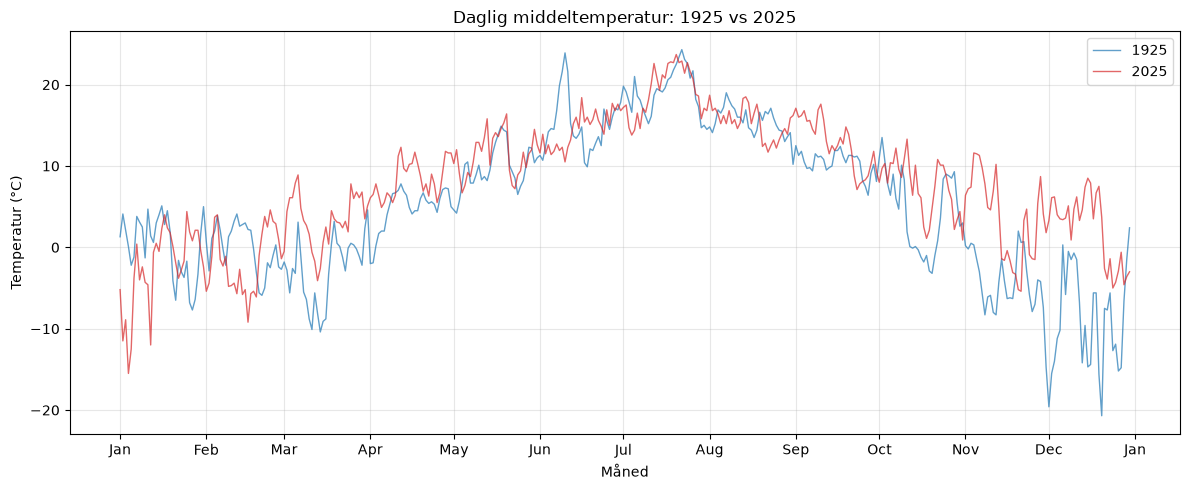

Sammendrag av daglig middeltemperatur (°C)
              1925  2025
Gjennomsnitt   5.3   7.9
Median         5.3   8.4
Min          -20.7 -15.5
Maks          24.3  23.7


In [11]:
old = get_frost_periods('SN17850', 'mean(air_temperature P1D)', '1925-01-01', '1925-12-31', client_id)
new = df['temperature']


def to_common_year(s):
    s = s.copy()
    s.index = pd.to_datetime({'year': 2001, 'month': s.index.month, 'day': s.index.day})
    return s

old_c = to_common_year(old)
new_c = to_common_year(new)

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(old_c.index, old_c.values, color='tab:blue', alpha=0.7, linewidth=1, label='1925')
ax.plot(new_c.index, new_c.values, color='tab:red', alpha=0.7, linewidth=1, label='2025')
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b'))
ax.set_title('Daglig middeltemperatur: 1925 vs 2025')
ax.set_xlabel('Måned')
ax.set_ylabel('Temperatur (°C)')
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()

summary = pd.DataFrame({
    "1925": [
        old.mean(),
        old.median(),
        old.min(),
        old.max()
    ],
    "2025": [
        new.mean(),
        new.median(),
        new.min(),
        new.max()
    ]
}, index=["Gjennomsnitt", "Median", "Min", "Maks"])

print("Sammendrag av daglig middeltemperatur (°C)")
print(summary.to_string(float_format=lambda value: f"{value:.1f}"))

# Task 4

In [12]:
%pip install pyyaml

  Using cached pyyaml-6.0.3-cp314-cp314-win_amd64.whl.metadata (2.4 kB)
Using cached pyyaml-6.0.3-cp314-cp314-win_amd64.whl (156 kB)
Note: you may need to restart the kernel to use updated packages.


In [13]:
import yaml


def count_heatwaves(station_id, year, output_file=None):
    # Hent daglig makstemperatur, ikke middeltemperatur.
    temperatures = get_frost_periods(
        station_id,
        "max(air_temperature P1D)",
        f"{year}-01-01",
        f"{year}-12-31",
        client_id
    )

    # Ta med alle kalenderdagene.
    # Manglende temperatur blir NaN og bryter en hetebølge.
    days = pd.date_range(f"{year}-01-01", f"{year}-12-31")
    temperatures = temperatures.reindex(days)

    heatwaves = []
    start = None
    duration = 0

    for date, temperature in temperatures.items():
        if pd.notna(temperature) and temperature >= 27:
            if duration == 0:
                start = date

            duration += 1

        else:
            if duration >= 5:
                heatwaves.append({
                    "start": start.strftime("%Y-%m-%d"),
                    "end": (date - pd.Timedelta(days=1)).strftime("%Y-%m-%d"),
                    "days": duration
                })

            start = None
            duration = 0

    # Ta også med en eventuell hetebølge som slutter 31. desember.
    if duration >= 5:
        heatwaves.append({
            "start": start.strftime("%Y-%m-%d"),
            "end": days[-1].strftime("%Y-%m-%d"),
            "days": duration
        })

    summary = {
        "station_id": station_id,
        "year": int(year),
        "number_of_heatwaves": len(heatwaves),
        "heatwaves": heatwaves
    }

    if output_file is None:
        output_file = f"heatwaves_{station_id}_{year}.yml"

    with open(output_file, "w", encoding="utf-8") as file:
        yaml.safe_dump(
            summary,
            file,
            allow_unicode=True,
            sort_keys=False
        )

    print(f"Antall hetebølger i {year}: {len(heatwaves)}")
    print(f"Resultatet er lagret i {output_file}")

    return summary

summary = count_heatwaves("SN17850", 2025)


Antall hetebølger i 2025: 1
Resultatet er lagret i heatwaves_SN17850_2025.yml


# Task 5

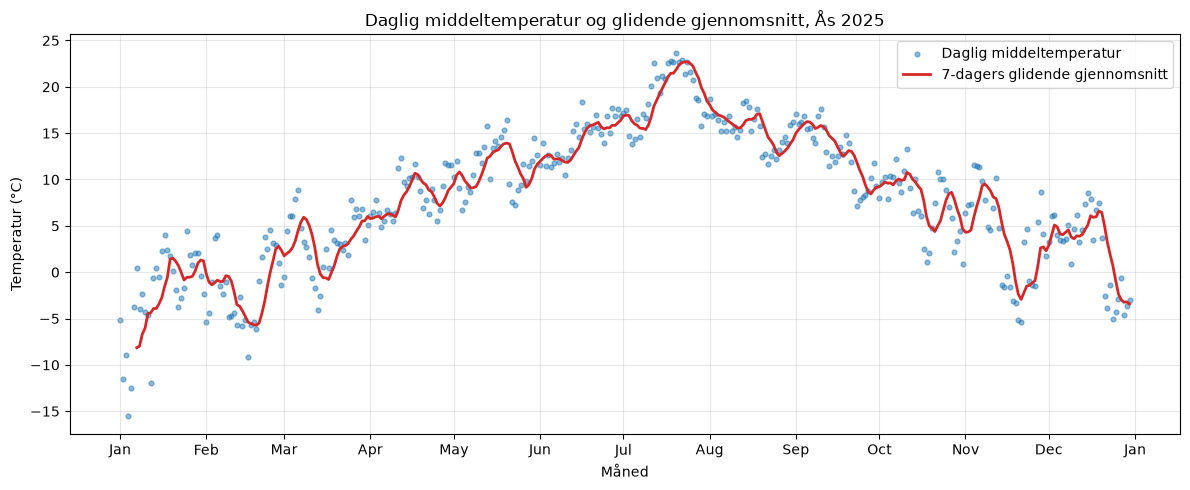

In [14]:
def moving_average(temperatures):
    temperatures = temperatures.copy().sort_index()

    # Sett inn manglende kalenderdager.
    days = pd.date_range(
        temperatures.index.min(),
        temperatures.index.max()
    )
    temperatures = temperatures.reindex(days)

    return temperatures.rolling(window=7, min_periods=7).mean()


# Bruk temperaturdataene fra oppgave 1.
temperature = df["temperature"].copy().sort_index()
average = moving_average(temperature)

fig, ax = plt.subplots(figsize=(12, 5))

# Daglige temperaturer som punkter.
ax.scatter(
    temperature.index,
    temperature.values,
    color="tab:blue",
    s=12,
    alpha=0.5,
    label="Daglig middeltemperatur"
)

# Glidende gjennomsnitt som linje.
ax.plot(
    average.index,
    average.values,
    color="tab:red",
    linewidth=2,
    label="7-dagers glidende gjennomsnitt"
)

ax.set_title("Daglig middeltemperatur og glidende gjennomsnitt, Ås 2025")
ax.set_xlabel("Måned")
ax.set_ylabel("Temperatur (°C)")

ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))

ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()